In [118]:
import numpy as np
import matplotlib.pyplot as plt
from math import sqrt
from sys import maxsize
from time import sleep

x = np.array([
    [3.0, 3.4], [2.6, 1.8], [2.4, 1.7], [3.1, 4.7], [2.4, 2.2],
    [3.6, 3.5], [3.1, 1.8], [3.0, 3.9], [1.3, 2.4], [0.5, 1.3],
    [4.1, 4.2], [4.9, 4.9], [6.7, 4.3], [3.2, 3.8], [6.4, 4.6],
    [4.5, 3.9], [5.2, 3.4], [7.9, 3.5], [6.5, 5.6], [5.7, 4.4],
    [4.1, 8.1], [2.4, 8.1], [5.8, 6.0], [5.1, 8.2], [3.2, 10.0],
    [5.0, 6.4], [4.1, 8.7], [3.8, 8.9], [3.9, 8.9], [5.9, 7.1]
])

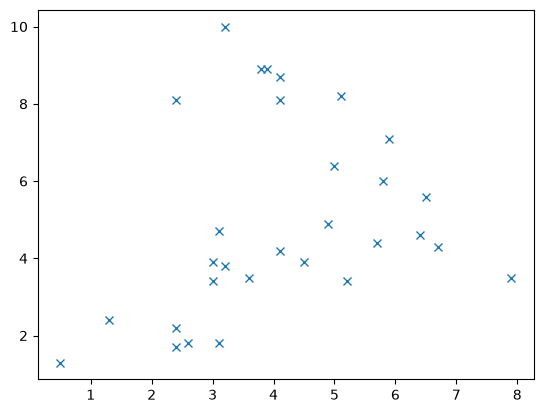

In [119]:
one = list()
two = list()

for i in x:
    one.append(i[0])
    two.append(i[1])

plt.plot(one, two, linestyle = "None", marker = "x")

In [140]:
# np.random.seed(0)

centroids = np.random.uniform(low = x.min(axis = 0), high = x.max(axis = 0), size = (3, 2))

centers = dict()
centers["A"] = centroids[0].tolist()
centers["B"] = centroids[1].tolist()
centers["C"] = centroids[2].tolist()

In [141]:
centroids

array([[2.00639758, 5.48299629],
       [5.50536255, 8.59626995],
       [5.1031348 , 5.6304258 ]])

In [142]:
A = "A"
B = "B"
C = "C"
centers

{'A': [2.006397579038828, 5.482996288632192],
 'B': [5.505362545009331, 8.596269950526136],
 'C': [5.1031348037395405, 5.630425803322552]}

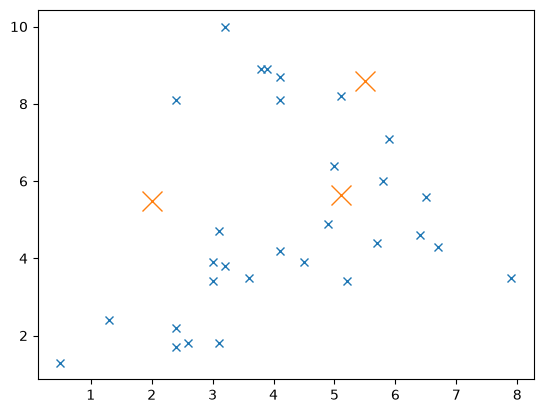

In [143]:
plt.plot(one, two, linestyle = "None", marker = "x")
plt.plot(centroids[:, 0], centroids[:, 1], linestyle="None", marker="x", markersize=15)
plt.show()

In [144]:
points = dict()
points["A"] = list()
points["B"] = list()
points["C"] = list()

In [145]:
for i in centers.items():
    print(i[1])

[2.006397579038828, 5.482996288632192]
[5.505362545009331, 8.596269950526136]
[5.1031348037395405, 5.630425803322552]


In [65]:
def distanceCalculator(point, dist = maxsize):
    result = -1
    for i in centers.items():
        distance = sqrt((i[1][0] - point[0])**2 + (i[1][1] - point[1])**2)

        if distance < dist:
            dist = distance
            result = i[0]

    return result

In [66]:
distanceCalculator([2, 2])

'A'

In [21]:
for i in x:
    centeroid = distanceCalculator(i)
    points[centeroid].append(i.tolist())

In [58]:
for k in points.keys():
    if len(points[k]) > 0:
        centers[k] = (sum(i[0] for i in points[k]) / len(points[k]), sum(i[1] for i in points[k]) / len(points[k]))

centers

{'A': (1.2571428571428573, 4.335714285714286),
 'B': (8.5375, 8.525),
 'C': (2.1, 8.15)}

In [136]:
print(centroids)

[[7.54295197 9.68329292]
 [3.33745601 1.70968407]
 [6.77503694 8.04832606]]


In [146]:
for ac in range(20):
    for i in x:
        centeroid = distanceCalculator(i)
        points[centeroid].append(i.tolist())

    for k in points.keys():
        if len(points[k]) > 0:
            centers[k] = (sum(i[0] for i in points[k]) / len(points[k]), sum(i[1] for i in points[k]) / len(points[k]))
            centroids[0] = centers[A]
            centroids[1] = centers[B]
            centroids[2] = centers[C]

        if ac < 19:
            points[k] = list()

In [147]:
points

{'A': [[3.0, 3.4],
  [2.6, 1.8],
  [2.4, 1.7],
  [3.1, 4.7],
  [2.4, 2.2],
  [3.6, 3.5],
  [3.1, 1.8],
  [3.0, 3.9],
  [1.3, 2.4],
  [0.5, 1.3],
  [3.2, 3.8]],
 'B': [[4.1, 8.1],
  [2.4, 8.1],
  [5.1, 8.2],
  [3.2, 10.0],
  [4.1, 8.7],
  [3.8, 8.9],
  [3.9, 8.9],
  [5.9, 7.1]],
 'C': [[4.1, 4.2],
  [4.9, 4.9],
  [6.7, 4.3],
  [6.4, 4.6],
  [4.5, 3.9],
  [5.2, 3.4],
  [7.9, 3.5],
  [6.5, 5.6],
  [5.7, 4.4],
  [5.8, 6.0],
  [5.0, 6.4]]}

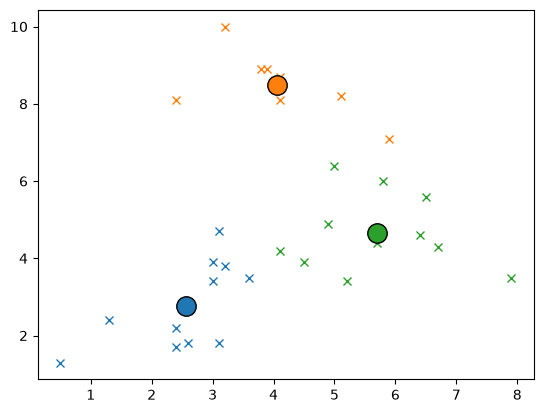

In [ ]:
colors = {"A": "tab:blue", "B": "tab:orange", "C": "tab:green"}

for k in points.keys():
    if len(points[k]) > 0:
        g = np.array(points[k])
        plt.plot(g[:, 0], g[:, 1], linestyle="None", marker="x", color=colors[k])
    plt.plot(centers[k][0], centers[k][1], linestyle="None", marker="o", markersize=14, color=colors[k], markeredgecolor="black")